---
tags: [algorithm, finance, variational]
---

# Portfolio Optimization with Pauli Correlation Encoding

This tutorial shows how to solve a portfolio-selection problem using Pauli correlation encoding (PCE). Following the workflow of {cite:t}`10.48550/arXiv.2511.21305`, we recursively partition a market graph with PCE and select one asset from each cluster. We implement the algorithm with Qamomile and emulate its quantum circuits with `qm.Reference()`, using `PauliCorrelationEncoding`, a `@qm.qkernel` ansatz, and sampled `Estimator` expectations. The example uses 30 S&P 500 tickers from 2013–2018 with a 4:1 chronological split.

In [1]:
# Install the latest Qamomile through pip!
# !pip install "qamomile[visualization]" kagglehub networkx pandas

In [2]:
from __future__ import annotations

import glob
import os
from collections import deque
from math import comb

import kagglehub
import matplotlib.pyplot as plt
import networkx as nx
import numpy as np
import pandas as pd
from scipy.optimize import minimize

import qamomile as qm
from qamomile.measurement import Estimator
from qamomile.optimization import BinaryModel, PauliCorrelationEncoding
from qamomile.stdlib import cx_entangling_layer

docs_test_mode = os.environ.get("QAMOMILE_DOCS_TEST") == "1"

## Background

Portfolio selection balances expected return against fluctuations in value. Portfolio variance depends on both individual return variances and the covariances between assets. Selecting assets that move less closely together can therefore reduce risk. Here, grouping related assets and choosing the highest-return representative of each group is a diversification heuristic; it does not directly solve a mean-variance optimization problem.

One motivation for applying quantum algorithms to portfolio selection is the possibility of speeding up combinatorial optimization. Standard QAOA and VQE encodings typically use one qubit per binary selection variable, limiting the number of assets that fit on a small device. Pauli correlation encoding (PCE), introduced by {cite:t}`10.1038/s41467-024-55346-z`, represents $m$ binary variables by the signs of $m$ $k$-body Pauli expectation values on $n = \mathcal{O}(m^{1/k})$ qubits for fixed $k$. See the [PCE MaxCut tutorial](pce_maxcut.ipynb) for the basics of PCE (encoding, loss function, and decoding). Here we focus on applying one PCE cut repeatedly to a market graph.

## Problem Settings

This tutorial uses version 4 of Kaggle's `camnugent/sandp500` dataset. It contains 619,040 daily records for 505 S&P 500 tickers from February 8, 2013 through February 7, 2018, with open, high, low, and close prices and trading volume. Of these tickers, 470 have closing prices for every trading date in the dataset.

Keep tickers with a complete closing-price history, then take the first `M = 30` in alphabetical order. Compute daily percentage returns and split them chronologically in a 4:1 ratio: the first 80% is used for graph construction and representative selection, and the final 20% for evaluation. These are the dataset's closing prices, without an additional adjustment for splits or dividends, so the result is an illustrative comparison rather than a total-return backtest.

In [3]:
M = 6 if docs_test_mode else 30

## Algorithm

Build a correlation graph of the assets, repeatedly split it in two by solving MaxCut with PCE until the target number of clusters is reached, then select one representative per cluster and evaluate their equal-weight portfolio. Clustering aims at diversification, while selecting the highest training-return asset in each cluster targets return. This selection can bring correlated high-return assets back together across clusters, so lower correlation among the final representatives is not guaranteed.

### Market Graph and Recursive MaxCut

Each asset is a node. Using training returns $r_i$ with standard deviations $\sigma_i$, define the correlation $\rho_{ij} = \mathrm{Cov}(r_i,r_j)/(\sigma_i\sigma_j)$ and retain an edge only when its absolute correlation exceeds $\lambda$:

```{math}
:label: eq-portfolio-weight
w_{ij} = 1 - |\rho_{ij}| \quad\text{for } |\rho_{ij}| > \lambda.
```

Pairs at or below the threshold have no edge. All graph statistics come from the training period. Here $m$ is the number of assets in the universe (`M`), and $m_a$ is the number of active, non-isolated nodes in a particular cut (`n_var`). We use $\lambda=0.25$ and six successful cuts, producing seven nonempty clusters in breadth-first order.

Equation {eq}`eq-portfolio-weight` gives weaker retained correlations larger edge weights. MaxCut seeks a partition with a large total crossing weight, aiming to separate less related assets while retaining more related assets together. The threshold and the global cut objective make this a heuristic.

For binary cluster labels $x_i\in\{0,1\}$, introduce spins $s_i=2x_i-1\in\{-1,1\}$. The weighted cut becomes

```{math}
:label: eq-portfolio-cut
\mathrm{Cut}(\mathcal G,\boldsymbol s)
= \frac12\sum_{(i,j)\in E}w_{ij}(1-s_i s_j).
```

Thus maximizing the cut is equivalent to minimizing $\sum_{(i,j)\in E}w_{ij}s_i s_j$.

In [4]:
LAMBDA = 0.25
n_splits = 1 if docs_test_mode else 6

### PCE for One Cut

Encode the active nodes with PCE, prepare a parameterized quantum state, and substitute $z_i=\tanh(\alpha\langle\Pi_i\rangle)$ for each spin in Equation {eq}`eq-portfolio-cut`. Following the portfolio paper's normalization, minimize

```{math}
:label: eq-portfolio-loss
\mathcal L = \sum_{(i,j)\in E}w_{ij}z_i z_j
+ \beta\nu\left(\frac1{m_a}\sum_i z_i^2\right)^2,\qquad
\nu=\frac W2+\frac{\bar w(m_a-1)}4.
```

Here $W=\sum_{(i,j)\in E}w_{ij}$ and $\bar w=W/|E|$. The [PCE tutorial](pce_maxcut.ipynb) explains the relaxation and regularizer. Our data term uses $w_{ij}$ rather than the Ising coefficient $w_{ij}/2$; this scale matters relative to the regularizer. Use correlator order $k=2$, $\beta=0.5$, and the paper's tuning rule $\alpha=n^{\lfloor k/2\rfloor}$. This is not a proven optimal value of $\alpha$; `ALPHA = None` applies the rule for each cut, and an explicit number overrides it. After optimizing the circuit parameters, decode positive expectations as $+1$ and nonpositive expectations as $-1$. Isolated nodes do not affect the cut and are assigned separately.

:::{note}
Qamomile's encoding includes mixed Pauli strings such as $X_iY_j$, whereas the portfolio paper uses strings with only $X$, only $Y$, or only $Z$ on the non-identity positions. The variable-to-operator mapping therefore differs, and the required qubit count can also change. We adapt the paper's portfolio workflow using Qamomile's encoding.
:::

In [5]:
K = 2
ALPHA = None
BETA = 0.5

### Representative Selection

For each final cluster $L_\ell$, select its highest mean training-return asset:

```{math}
:label: eq-portfolio-selection
v_\ell^* = \operatorname*{arg\,max}_{v\in L_\ell}
\overline r_v^{\,\mathrm{train}}.
```

This targets return while the clustering aims at diversification. The highest-return representatives may still be correlated across clusters; choosing one per cluster does not itself enforce low pairwise correlation. Evaluate their equal-weight portfolio on the held-out period.

## Implementation with Qamomile

### Preparing the Data

Pin the dataset version so repeated runs use the same input.

In [6]:
if docs_test_mode:
    rng = np.random.default_rng(42)
    market = rng.normal(0.0005, 0.006, (80, 1))
    daily = market + rng.normal(0.0, 0.008, (80, M))
    synthetic_prices = 100.0 * np.cumprod(1.0 + daily, axis=0)
    raw = (
        pd.DataFrame(
            synthetic_prices,
            index=pd.date_range("2020-01-01", periods=80, freq="B", name="date"),
            columns=[f"ASSET{i:02d}" for i in range(M)],
        )
        .reset_index()
        .melt(id_vars="date", var_name="name", value_name="close")
    )
else:
    path = kagglehub.dataset_download("camnugent/sandp500/versions/4")
    csv_candidates = glob.glob(
        os.path.join(path, "**", "all_stocks_5yr.csv"), recursive=True
    )
    assert len(csv_candidates) == 1
    raw = pd.read_csv(csv_candidates[0])

raw.columns = [c.lower() for c in raw.columns]
raw["date"] = pd.to_datetime(raw["date"])
wide = raw.pivot(index="date", columns="name", values="close").sort_index()
wide = wide.loc[:, wide.notna().all()]
assert wide.shape[1] >= M

tickers = sorted(wide.columns)[:M]
prices = wide[tickers]
returns = prices.pct_change().dropna()
split = int(len(returns) * 0.8)
train, test = returns.iloc[:split], returns.iloc[split:]
assert len(tickers) == M and len(train) > 1 and len(test) > 1
assert train.index[-1] < test.index[0]
assert np.isfinite(returns.to_numpy()).all()

print(f"tickers: {tickers}")
print(f"train: {train.shape} ({train.index[0].date()} - {train.index[-1].date()})")
print(f"test : {test.shape} ({test.index[0].date()} - {test.index[-1].date()})")

tickers: ['A', 'AAL', 'AAP', 'AAPL', 'ABBV', 'ABC', 'ABT', 'ACN', 'ADBE', 'ADI', 'ADM', 'ADP', 'ADS', 'ADSK', 'AEE', 'AEP', 'AES', 'AET', 'AFL', 'AGN', 'AIG', 'AIV', 'AIZ', 'AJG', 'AKAM', 'ALB', 'ALGN', 'ALK', 'ALL', 'ALXN']
train: (1006, 30) (2013-02-11 - 2017-02-07)
test : (252, 30) (2017-02-08 - 2018-02-07)


### Constructing the Market Graph

Inspect the density for several thresholds. The paper reports densities between 0.53 and 0.87, but does not specify $\lambda$. Our chosen value, `LAMBDA = 0.25`, gives a density in that range for this 30-asset instance; changing `M` may require revisiting the threshold.

lambda=0.10  density=1.000
lambda=0.15  density=0.977
lambda=0.20  density=0.892
lambda=0.25  density=0.766
lambda=0.30  density=0.579
lambda=0.35  density=0.326
lambda=0.40  density=0.163
lambda=0.45  density=0.074
lambda=0.50  density=0.032
lambda=0.55  density=0.018
lambda=0.60  density=0.007
nodes=30, edges=333, density=0.766
isolated: []


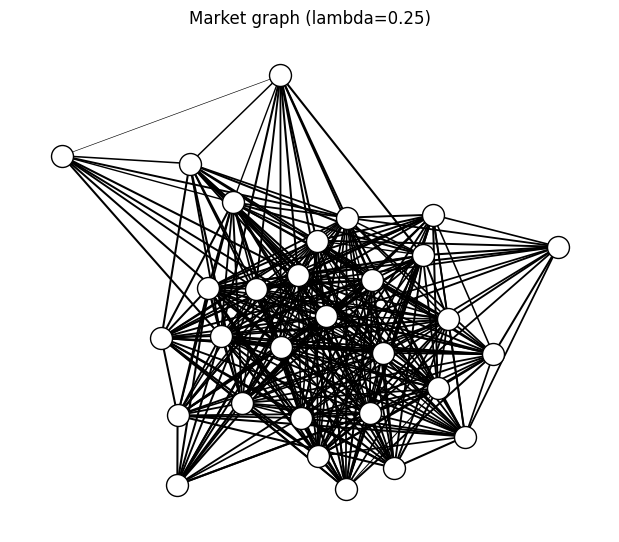

In [7]:
rho = train.corr().to_numpy()
for lam in np.arange(0.10, 0.65, 0.05):
    adjacency = (np.abs(rho) > lam) & ~np.eye(M, dtype=bool)
    candidate = nx.from_numpy_array(adjacency)
    print(f"lambda={lam:.2f}  density={nx.density(candidate):.3f}")

G = nx.Graph()
G.add_nodes_from(range(M))
nx.set_node_attributes(G, {i: t for i, t in enumerate(tickers)}, "ticker")
for i in range(M):
    for j in range(i + 1, M):
        if abs(rho[i, j]) > LAMBDA:
            G.add_edge(i, j, weight=1.0 - abs(rho[i, j]))

assert G.number_of_nodes() == M and G.number_of_edges() > 0
print(f"nodes={M}, edges={G.number_of_edges()}, density={nx.density(G):.3f}")
print(f"isolated: {[tickers[v] for v in G if G.degree(v) == 0]}")

pos = nx.spring_layout(G, seed=1)
plt.figure(figsize=(6, 5))
nx.draw(
    G,
    pos,
    node_size=250,
    node_color="white",
    edgecolors="black",
    width=[2 * d["weight"] for _, _, d in G.edges(data=True)],
)
plt.title(f"Market graph (lambda={LAMBDA})")
plt.show()

### Implementing the Ansatz with `@qkernel`

A hardware-efficient ansatz (HEA) consists here of single-qubit rotations followed by a fixed entangling layer. Start in a uniform superposition, then repeat $R_y$ and $R_z$ rotations followed by a CX entangling layer. `DEPTH = None` uses $p=\max(1,\lfloor m_a/n\rfloor)$ layers for each cut; an integer fixes the layer count instead.

The `@qkernel` declares the width, layer count, and parameter-vector length as constants; angles are parameters. Each of the $p$ layers uses $2n$ angles, so `count = 2 * nq * layers`.

In [8]:
DEPTH = None


@qm.qkernel
def hea(
    width: qm.Const[qm.Int],
    layers: qm.Const[qm.Int],
    count: qm.Const[qm.Int],
    thetas: qm.Param[qm.Vector[qm.Real, count]],  # noqa: F821
) -> qm.Q[qm.Bits[width]]:  # noqa: F821
    q = qm.qubits(width)
    q = qm.h(q)
    for d in range(layers):
        offset = d * 2 * width
        for i in range(width):
            q = qm.ry(q, thetas[offset + i], target=i)
        for i in range(width):
            q = qm.rz(q, thetas[offset + width + i], target=i)
        q = cx_entangling_layer(q, width)
    return q


executor = qm.Reference()
SHOTS_PER_OBSERVABLE = 2 if docs_test_mode else 1_024
MEASUREMENT_SEED = 100

### Encoding and Sampled Expectations

Remove isolated nodes and map the remaining node identifiers to consecutive indices. `BinaryModel.from_ising` receives couplings $J_{ij}=w_{ij}/2$ and offset $-W/2$, making its energy exactly minus Equation {eq}`eq-portfolio-cut`. `PauliCorrelationEncoding` then supplies one observable per active variable.

`qm.specialize` fixes the HEA dimensions for this cut. One reusable `Estimator` per observable binds each trial parameter vector and estimates its expectation with `qm.Reference()`, using 1,024 measurements per observable. Fixed, distinct nonzero seeds make repeated evaluations reproducible. These estimates contain sampling noise, so the optimized partition can differ from one obtained with exact expectations.

In [9]:
def encode_subgraph(sub, active):
    """Encode weighted MaxCut using consecutive active-node indices."""
    index = {v: i for i, v in enumerate(active)}
    couplings = {
        (index[u], index[v]): 0.5 * data["weight"]
        for u, v, data in sub.edges(data=True)
    }
    total_weight = sum(data["weight"] for _, _, data in sub.edges(data=True))
    encoding = PauliCorrelationEncoding(
        BinaryModel.from_ising(couplings, constant=-total_weight / 2.0),
        correlator_order=K,
    )
    n_var, nq = len(active), encoding.num_qubits
    assert len(encoding.observables) == n_var
    assert comb(nq, K) * 3**K >= n_var
    assert nq == K or comb(nq - 1, K) * 3**K < n_var
    return encoding, index, total_weight


def sampled_expectations(encoding, n_var):
    """Create a sampled expectation evaluator for a specialized HEA."""
    nq = encoding.num_qubits
    layers = DEPTH if DEPTH is not None else max(1, n_var // nq)
    count = 2 * nq * layers
    program = qm.specialize(hea, width=nq, layers=layers, count=count)
    estimators = tuple(
        Estimator(program, observable) for observable in encoding.observables
    )

    def expectations(theta):
        parameters = {"thetas": tuple(float(v) for v in theta)}
        return [
            estimator.estimate(
                on=executor,
                parameters=parameters,
                shots=SHOTS_PER_OBSERVABLE,
                seed=MEASUREMENT_SEED + i,
            ).value
            for i, estimator in enumerate(estimators)
        ]

    return expectations, count

### Optimizing the Loss and Decoding the Result

`encoding.model` exposes the encoded Ising model. This MaxCut construction has no linear terms. Compute the data term from the graph weights to retain the normalization in Equation {eq}`eq-portfolio-loss`. The regularizer uses the active-node count and the current subgraph's weight scale.

COBYLA optimizes the circuit parameters without gradients. Use `MAXITER = 200` as the evaluation budget and `SEED = 42` for the initial parameters. After minimizing the loss, use the signs of the sampled expectations to assign the two groups.

In [10]:
MAXITER = 5 if docs_test_mode else 200
SEED = 42


def make_loss(sub, index, expectations, alpha, nu):
    """Build the portfolio paper's relaxed loss with quartic regularization."""

    def loss(theta):
        relaxed = [np.tanh(alpha * value) for value in expectations(theta)]
        data_term = sum(
            data["weight"] * relaxed[index[u]] * relaxed[index[v]]
            for u, v, data in sub.edges(data=True)
        )
        return (
            data_term
            + BETA * nu * (sum(value * value for value in relaxed) / len(relaxed)) ** 2
        )

    return loss


cut_qubits = []


def bipartition(sub):
    """Return a spin label for each node, including isolated nodes."""
    nodes = sorted(sub.nodes())
    active = [v for v in nodes if sub.degree(v) > 0]
    isolated = [v for v in nodes if sub.degree(v) == 0]
    if len(active) < 2:
        return {v: (1 if i < len(nodes) // 2 else -1) for i, v in enumerate(nodes)}

    encoding, index, total_weight = encode_subgraph(sub, active)
    n_var, nq = len(active), encoding.num_qubits
    assert all(len(indices) == 2 for indices in encoding.model.coefficients)
    expectations, count = sampled_expectations(encoding, n_var)
    alpha = float(nq ** (K // 2)) if ALPHA is None else float(ALPHA)
    mean_weight = total_weight / sub.number_of_edges()
    nu = total_weight / 2.0 + mean_weight * (n_var - 1) / 4.0
    loss = make_loss(sub, index, expectations, alpha, nu)
    initial = np.random.default_rng(SEED).uniform(-np.pi, np.pi, count)
    options = {"maxiter": max(MAXITER, count + 2)}
    if docs_test_mode:
        options["f_target"] = float("inf")
    result = minimize(loss, initial, method="COBYLA", options=options)
    values = np.asarray(expectations(result.x))
    assert np.isfinite(result.fun) and np.isfinite(values).all()
    assert np.all(np.abs(values) <= 1.0 + 1e-10)

    labels = {v: (1 if values[index[v]] > 0 else -1) for v in active}
    for i, v in enumerate(isolated):
        labels[v] = 1 if i % 2 == 0 else -1
    cut_qubits.append(nq)
    print(
        f"      variables={n_var:3d} qubits={nq} ({n_var / nq:.1f}x) "
        f"loss={result.fun:+.3f} |<P>|med={np.median(np.abs(values)):.4f}"
    )
    return labels

### Recursive Partitioning

Apply the cut to the next splittable cluster in the queue. A cut whose signs all agree does not consume the split budget.

In [11]:
queue = deque([sorted(G.nodes())])
done = []
remaining = n_splits

while remaining > 0 and queue:
    nodes = queue.popleft()
    if len(nodes) <= 1:
        done.append(nodes)  # Cannot split; use the remaining budget elsewhere.
        continue

    sp = bipartition(G.subgraph(nodes))
    s1 = [v for v in nodes if sp[v] > 0]
    s2 = [v for v in nodes if sp[v] <= 0]

    if not s1 or not s2:
        # Identical signs indicate collapse despite regularization.
        print(f"  [warn] collapse on {len(nodes)} nodes -- check alpha/beta")
        done.append(nodes)
        continue

    print(f"  split {len(nodes):3d} -> {len(s1):3d} + {len(s2):3d}")
    queue.append(s1)
    queue.append(s2)
    remaining -= 1

clusters = done + list(queue)
print(f"\nclusters: {[len(c) for c in clusters]}")
assert len(clusters) == n_splits + 1
assert all(clusters)
assert sorted(v for cluster in clusters for v in cluster) == list(range(M))
if not docs_test_mode:
    assert max(cut_qubits) == 4
print(f"qubits per optimized cut: {cut_qubits}")

      variables= 30 qubits=4 (7.5x) loss=-4.076 |<P>|med=0.1523
  split  30 ->  13 +  17


      variables= 13 qubits=3 (4.3x) loss=-1.002 |<P>|med=0.1465
  split  13 ->   7 +   6


      variables= 17 qubits=3 (5.7x) loss=-4.061 |<P>|med=0.2285
  split  17 ->   8 +   9


      variables=  7 qubits=2 (3.5x) loss=-0.373 |<P>|med=0.1543
  split   7 ->   4 +   3


      variables=  6 qubits=2 (3.0x) loss=-1.123 |<P>|med=0.3711
  split   6 ->   3 +   3


      variables=  8 qubits=2 (4.0x) loss=-2.230 |<P>|med=0.5557
  split   8 ->   3 +   5

clusters: [9, 4, 3, 3, 3, 3, 5]
qubits per optimized cut: [4, 3, 3, 2, 2, 2]


Visualize the partitioned graph.

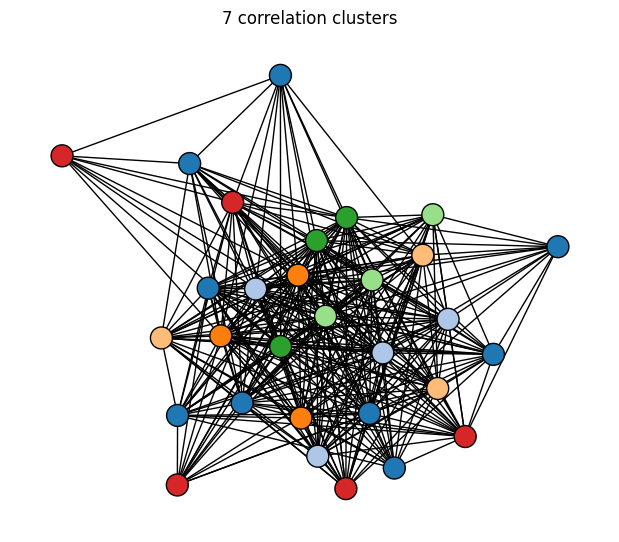

In [12]:
# Visualize the final partition.
color = {}
for ci, c in enumerate(clusters):
    for v in c:
        color[v] = ci

plt.figure(figsize=(6, 5))
nx.draw(
    G,
    pos,
    node_size=250,
    edgecolors="black",
    cmap=plt.cm.tab20,
    node_color=[color[v] for v in G.nodes()],
    vmin=0,
    vmax=19,
)
plt.title(f"{len(clusters)} correlation clusters")
plt.show()

### Selecting Representatives

Apply Equation {eq}`eq-portfolio-selection` using training returns only. Each selected ticker belongs to a different cluster; no held-out return enters this selection.

In [13]:
mu = train.mean().to_numpy()
reps = [max(cluster, key=lambda v: mu[v]) for cluster in clusters]
selected_tickers = [tickers[v] for v in reps]
assert len(reps) == len(clusters)
assert len(set(selected_tickers)) == len(reps)
assert all(v in cluster for v, cluster in zip(reps, clusters))
print(f"selected {len(reps)} assets: {selected_tickers}")

selected 7 assets: ['ALGN', 'AET', 'ADBE', 'ALK', 'ALL', 'AGN', 'AAL']


## Results

### Correlation Check

Compare mean pairwise absolute correlation among the selected assets with that of the full training universe. Lower values would support the diversification rationale. This diagnostic is not guaranteed to improve: MaxCut is approximate, and highest-return representative selection can increase correlations.

In [14]:
def mean_absolute_correlation(correlation):
    """Average the upper-triangle off-diagonal absolute correlations."""
    pairs = np.triu_indices(len(correlation), k=1)
    return float(np.abs(correlation[pairs]).mean())


universe_correlation = mean_absolute_correlation(rho)
selected_correlation = mean_absolute_correlation(rho[np.ix_(reps, reps)])
assert np.isfinite([universe_correlation, selected_correlation]).all()
assert 0 <= universe_correlation <= 1 and 0 <= selected_correlation <= 1
print(
    f"mean |rho|: selected={selected_correlation:.3f}, universe={universe_correlation:.3f}"
)

mean |rho|: selected=0.317, universe=0.316


### Held-Out Portfolio Performance

Average the selected assets' daily test returns and compound them from an initial value of 1,000. This corresponds to daily rebalancing to equal weights, without transaction costs. The baseline does the same with all `M` assets. Report the annualized Sharpe ratio with a zero risk-free rate:

```{math}
:label: eq-portfolio-sharpe
S = \sqrt{252}\,\frac{\overline r_p}{\mathrm{std}(r_p)}.
```

It measures return per unit of return volatility. Both portfolios use the same held-out dates and evaluation convention.

PCE      final =  1266.68   sharpe = +1.837
baseline final =  1149.85   sharpe = +1.564


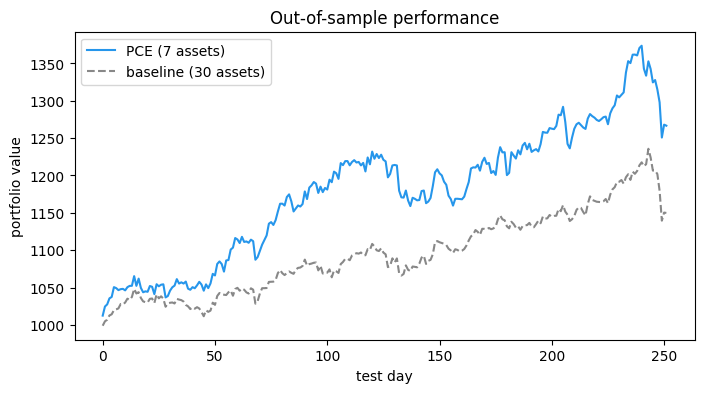

In [15]:
def sharpe(r: pd.Series) -> float:
    """Calculate annualized Sharpe with a zero risk-free rate."""
    std = r.std()
    return float(np.sqrt(252) * r.mean() / std) if std > 0 else 0.0


pce_returns = test[selected_tickers].mean(axis=1)
baseline_returns = test.mean(axis=1)
equity = 1000 * (1 + pce_returns).cumprod()
baseline = 1000 * (1 + baseline_returns).cumprod()
assert np.isfinite(sharpe(pce_returns))
assert np.isfinite(sharpe(baseline_returns))
assert np.isfinite(equity).all() and np.isfinite(baseline).all()
assert equity.iloc[-1] > 0 and baseline.iloc[-1] > 0

print(f"PCE      final = {equity.iloc[-1]:8.2f}   sharpe = {sharpe(pce_returns):+.3f}")
print(
    f"baseline final = {baseline.iloc[-1]:8.2f}   sharpe = {sharpe(baseline_returns):+.3f}"
)

plt.figure(figsize=(8, 4))
plt.plot(equity.values, label=f"PCE ({len(reps)} assets)", color="#2696EB")
plt.plot(baseline.values, label=f"baseline ({M} assets)", color="#888", ls="--")
plt.xlabel("test day")
plt.ylabel("portfolio value")
plt.legend()
plt.title("Out-of-sample performance")
plt.show()

With the settings used in this tutorial, the selected portfolio ends above the all-asset baseline and has a higher Sharpe ratio. However, its mean training-period absolute correlation is higher, so this run does not demonstrate improved diversification by that measure. These are results for one chronological split and one optimizer seed, not evidence of generally better returns or quantum advantage. We do not compare against a classical portfolio optimizer or reproduce the paper's 250-asset study.

## Summary

- `PauliCorrelationEncoding` maps the first 30-variable cut to four qubits; subsequent cuts use two or three qubits in this example.
- A Qamomile HEA and sampled reference expectations drive the PCE loss, followed by recursive graph partitioning and training-only representative selection.
- This example's seven-asset portfolio exceeds the equal-weight baseline in final value and Sharpe ratio, but not in the correlation diagnostic.
- The experiment is a small simulation with one split and seed. The qubit reduction alone establishes neither runtime advantage nor investment value.